In [1]:
# import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
# 2. Load the dataset

In [4]:
# Load dataset
df = pd.read_csv("supply_chain-regression-datasets.csv")

# Display first 5 records
print(df.head())

# Dataset information
print(df.info())

# Dataset shape
print("Dataset Shape:", df.shape)

       price  promotion  season  region_factor      demand
0  40.581311          0       6       1.016377  195.985224
1  95.317859          0       2       1.140376  132.900246
2  74.539424          0       4       1.122994  172.563549
3  61.872556          0       7       1.079543  303.389736
4  19.821771          0      11       1.041786  279.642914
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          10000 non-null  float64
 1   promotion      10000 non-null  int64  
 2   season         10000 non-null  int64  
 3   region_factor  10000 non-null  float64
 4   demand         10000 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 390.8 KB
None
Dataset Shape: (10000, 5)


In [5]:
# 3. Exploratory Data Analysis (EDA)

              price     promotion        season  region_factor        demand
count  10000.000000  10000.000000  10000.000000   10000.000000  10000.000000
mean      51.945158      0.307200      6.581400       1.000078    204.941396
std       27.324862      0.461356      3.428345       0.115172     79.133805
min        5.001105      0.000000      1.000000       0.800008    -44.817430
25%       28.401243      0.000000      4.000000       0.901918    148.901329
50%       51.790219      0.000000      7.000000       1.001356    203.893315
75%       75.300603      1.000000     10.000000       1.099750    260.053876
max       99.973179      1.000000     12.000000       1.199990    471.678740

Missing Values:
price            0
promotion        0
season           0
region_factor    0
demand           0
dtype: int64

Duplicate Records: 0


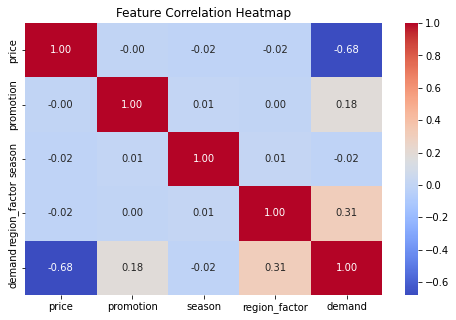

In [6]:
# Statistical summary
print(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [7]:
# 4. Define input features (X) and target (Y)

In [8]:
# Input features
X = df.drop("demand", axis=1)

# Target variable
y = df["demand"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
       price  promotion  season  region_factor
0  40.581311          0       6       1.016377
1  95.317859          0       2       1.140376
2  74.539424          0       4       1.122994
3  61.872556          0       7       1.079543
4  19.821771          0      11       1.041786

Target Variable:
0    195.985224
1    132.900246
2    172.563549
3    303.389736
4    279.642914
Name: demand, dtype: float64


In [9]:
# 5. Split the dataset

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 4)
Testing Data: (2000, 4)


In [11]:
# 6. Build and train Linear Regression model

In [12]:
# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [13]:
# 7. Make predictions

In [14]:
# Predict demand
y_pred = model.predict(X_test)

# Display actual vs predicted values
results = pd.DataFrame({
    "Actual Demand": y_test.values,
    "Predicted Demand": y_pred
})

print(results.head(10))

   Actual Demand  Predicted Demand
0     188.898075        218.858015
1     154.101150        137.130118
2     246.656647        217.102035
3     194.095413        333.740858
4     237.361427        192.369098
5     218.026709        203.416798
6     271.704832        257.280756
7     176.260679        146.317428
8     107.288634        157.221484
9     191.474833        238.046993


In [15]:
# 8. Evaluate the model

In [16]:
# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 39.55142871961831
MSE: 2510.636692580065
RMSE: 50.10625402661892
R2 Score: 0.5953925364043078


In [17]:
# 9. Visualize actual vs predicted demand

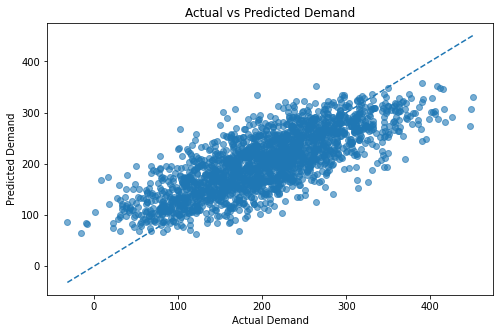

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title("Actual vs Predicted Demand")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [19]:
# 10. Feature coefficient interpretation

In [20]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print(coefficients)
print("\nIntercept:", model.intercept_)

         Feature  Coefficient
0          price    -1.950109
1      promotion    30.988726
2         season    -0.831959
3  region_factor   205.942223

Intercept: 96.37264311289073


In [21]:
# 11. Predict demand for a new product scenario

In [22]:
# Example new product information
new_data = pd.DataFrame({
    "price": [50],
    "promotion": [1],
    "season": [6],
    "region_factor": [1.10]
})

# Predict demand
predicted_demand = model.predict(new_data)

print("Predicted Product Demand:", predicted_demand[0])
print("Estimated Demand:", round(predicted_demand[0], 2), "units")

Predicted Product Demand: 251.40059369324814
Estimated Demand: 251.4 units
